<a href="https://colab.research.google.com/github/rounakjha52-cmd/ai-in-cybersecurity-assignment-1/blob/main/Lab_1_Recognizing_Cyber_Threats.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score

# Google Colab: upload the CSV if it is not already in the working directory.
if not os.path.exists("simple_cyber_messages.csv"):
    try:
        from google.colab import files
        uploaded = files.upload()
    except ImportError:
        print("Place simple_cyber_messages.csv in the notebook's working directory.")

df = pd.read_csv("simple_cyber_messages.csv")

required_columns = {"message_id", "message", "correct_category"}
missing = required_columns - set(df.columns)
if missing:
    raise ValueError(f"Dataset is missing required columns: {missing}")

display(df.head())
print("Dataset shape:", df.shape)
print("\nCategory counts:")
display(df["correct_category"].value_counts())

,message_id,message,correct_category
0,1,The department meeting is scheduled for 2 PM i...,Safe
1,2,Your account will be suspended. Click here and...,Phishing
2,3,The attached executable file contains a trojan...,Malware
3,4,Your files have been encrypted. Pay bitcoin to...,Ransomware
4,5,Library books must be returned before Friday.,Safe


Dataset shape: (28, 3)

Category counts:


,count
correct_category,
Safe,7
Phishing,7
Malware,7
Ransomware,7


## Q1. Manual Threat Identification (5 marks)

### Aim
Manually classify the first ten sample messages and identify the words that influenced each decision.

### Theory
- **Phishing:** urgency, account verification, password, OTP, bank, prize or login language.
- **Malware:** infected files, viruses, trojans, spyware, executables or suspicious attachments.
- **Ransomware:** encrypted or locked files, ransom, bitcoin, payment or restoration demands.
- **Safe:** no clear threat indicator is present and the context appears legitimate.

Read each message without opening any link or attachment. The important words below are examples of the indicators used for the manual review. Compare the manual labels with the dataset's `correct_category`.

In [2]:
manual_table = df.head(10)[
    ["message_id", "message", "correct_category"]
].copy()

important_words = [
    "department meeting, scheduled, Room 301",
    "suspended, click here, verify, password, urgently",
    "executable, trojan, infect",
    "encrypted, bitcoin, restore files",
    "library books, returned, Friday",
    "prize, login, claim",
    "spyware, attachment",
    "locked files, ransom, payment",
    "attendance report, official portal",
    "urgent, bank, verify, account, OTP"
]

manual_table["manual_category"] = [
    "Safe", "Phishing", "Malware", "Ransomware", "Safe",
    "Phishing", "Malware", "Ransomware", "Safe", "Phishing"
]
manual_table["important_words"] = important_words
manual_table["manual_matches_dataset"] = (
    manual_table["manual_category"] == manual_table["correct_category"]
)

display(manual_table)
print("Manual labels matching dataset:",
      manual_table["manual_matches_dataset"].sum(), "out of", len(manual_table))

,message_id,message,correct_category,manual_category,important_words,manual_matches_dataset
0,1,The department meeting is scheduled for 2 PM i...,Safe,Safe,"department meeting, scheduled, Room 301",True
1,2,Your account will be suspended. Click here and...,Phishing,Phishing,"suspended, click here, verify, password, urgently",True
2,3,The attached executable file contains a trojan...,Malware,Malware,"executable, trojan, infect",True
3,4,Your files have been encrypted. Pay bitcoin to...,Ransomware,Ransomware,"encrypted, bitcoin, restore files",True
4,5,Library books must be returned before Friday.,Safe,Safe,"library books, returned, Friday",True
5,6,Congratulations! You won a prize. Login now to...,Phishing,Phishing,"prize, login, claim",True
6,7,Antivirus detected spyware in the downloaded a...,Malware,Malware,"spyware, attachment",True
7,8,Locked files will be released only after ranso...,Ransomware,Ransomware,"locked files, ransom, payment",True
8,9,Your monthly attendance report is available on...,Safe,Safe,"attendance report, official portal",True
9,10,Urgent bank alert: verify account and share OT...,Phishing,Phishing,"urgent, bank, verify, account, OTP",True


Manual labels matching dataset: 10 out of 10


### Q1 – Observations
- Threat messages contain indicators such as requests to verify passwords, suspicious attachments, spyware, encrypted files or ransom demands.
- Safe messages can contain ordinary instructions or announcements. They should still be checked in context because a keyword alone does not prove that a message is safe or malicious.

## Q2. Keyword Lists and Rule-Based Classifier (10 marks)

### Aim
Create transparent keyword lists and a Python function that predicts a message category.

### Algorithm
1. Create keyword lists for Phishing, Malware and Ransomware.
2. Convert the message to lowercase.
3. Count matching keywords in each category.
4. Return `Safe` if all category scores are zero.
5. Otherwise, return the category with the highest score, matched words and score.

A rule-based classifier follows conditions explicitly written by a human. It is easy to explain, but may fail when attackers use unfamiliar wording or synonyms.

In [3]:
RULE_KEYWORDS = {
    "Phishing": [
        "click here", "verify", "password", "urgent",
        "otp", "prize", "bank", "login", "blocked"
    ],
    "Malware": [
        "malware", "virus", "infected", "attachment",
        "trojan", "spyware", "executable"
    ],
    "Ransomware": [
        "encrypted", "ransom", "bitcoin", "restore files",
        "locked files", "unlock", "payment demand"
    ]
}

def classify_message(message):
    message = str(message).lower()

    scores = {
        category: sum(keyword in message for keyword in keywords)
        for category, keywords in RULE_KEYWORDS.items()
    }

    predicted = max(scores, key=scores.get)

    if scores[predicted] == 0:
        return "Safe", "", 0

    matched = [
        keyword for keyword in RULE_KEYWORDS[predicted]
        if keyword in message
    ]
    return predicted, ", ".join(matched), scores[predicted]


# Test at least four messages, including one Safe example.
test_messages = [
    "The department meeting is scheduled for 2 PM.",
    "Urgent: click here to verify your password",
    "The executable contains a trojan virus.",
    "Your files are encrypted. Pay bitcoin to restore files."
]

for sample in test_messages:
    print(sample)
    print("Result:", classify_message(sample))
    print("-" * 70)

The department meeting is scheduled for 2 PM.
Result: ('Safe', '', 0)
----------------------------------------------------------------------
Urgent: click here to verify your password
Result: ('Phishing', 'click here, verify, password, urgent', 4)
----------------------------------------------------------------------
The executable contains a trojan virus.
Result: ('Malware', 'virus, trojan, executable', 3)
----------------------------------------------------------------------
Your files are encrypted. Pay bitcoin to restore files.
Result: ('Ransomware', 'encrypted, bitcoin, restore files', 3)
----------------------------------------------------------------------


### Q2 – Limitation
Keyword rules may miss synonyms, spelling variations, context and new attack language. A message containing a warning word may also be legitimate, so the result should not be treated as a final security decision.

## Q3. Complete Dataset Classification and Accuracy (10 marks)

### Aim
Apply the classifier to the complete dataset, compare predictions with the supplied labels, and calculate accuracy.

**Accuracy** is the proportion of correct predictions among all predictions:

\[
\text{Accuracy} = \frac{\text{Number of correct predictions}}{\text{Total predictions}} \times 100
\]

- **False positive:** a safe message incorrectly labelled as a threat.
- **False negative:** a threat incorrectly labelled as safe.

In [4]:
# Apply the classifier to every message.
results = df["message"].apply(classify_message)

df[["predicted_category", "matched_keywords", "keyword_score"]] = pd.DataFrame(
    results.tolist(), index=df.index
)

df["correct"] = df["correct_category"] == df["predicted_category"]

accuracy = accuracy_score(df["correct_category"], df["predicted_category"])
correct_predictions = int(df["correct"].sum())
incorrect_predictions = int((~df["correct"]).sum())

output_columns = [
    "message_id",
    "correct_category",
    "predicted_category",
    "matched_keywords",
    "keyword_score",
    "correct"
]
display(df[output_columns])

print("Correct predictions:", correct_predictions)
print("Incorrect predictions:", incorrect_predictions)
print(f"Accuracy: {accuracy * 100:.2f}%")

,message_id,correct_category,predicted_category,matched_keywords,keyword_score,correct
0,1,Safe,Safe,,0,True
1,2,Phishing,Phishing,"click here, verify, password, urgent",4,True
2,3,Malware,Malware,"trojan, executable",2,True
3,4,Ransomware,Ransomware,"encrypted, bitcoin, restore files",3,True
4,5,Safe,Safe,,0,True
5,6,Phishing,Phishing,"prize, login",2,True
6,7,Malware,Malware,"virus, attachment, spyware",3,True
7,8,Ransomware,Ransomware,"ransom, locked files",2,True
8,9,Safe,Safe,,0,True
9,10,Phishing,Phishing,"verify, urgent, otp, bank",4,True


Correct predictions: 27
Incorrect predictions: 1
Accuracy: 96.43%


### Q3 – Observation
The lab manual gives approximately **28 correct predictions out of 28 (100%)** as the expected result for the supplied classroom dataset. Your actual result is calculated from the CSV when this notebook runs.

Classroom accuracy can be optimistic because the sample is small and its messages may use the same wording as the keyword rules. Real attackers can change wording, use new techniques or deliberately avoid known keywords. A high score on this dataset does not prove real-world effectiveness.

## Q4. Risk Level, Recommended Action and Bar Chart (10 marks)

### Aim
Convert the predicted category and keyword score into a simple risk response and summarize the category counts.

### Risk rules
- **Safe:** Low risk – continue normal caution.
- **Ransomware**, or any detected threat with a keyword score of 2 or more: High risk – do not interact; isolate the system if required and report it.
- Other detected threats: Medium risk – do not interact; verify the sender and report the message.

In [5]:
def add_risk_and_action(row):
    if row["predicted_category"] == "Safe":
        return "Low", "Continue normal caution."

    if row["predicted_category"] == "Ransomware" or row["keyword_score"] >= 2:
        return "High", "Do not click/open; isolate if required and report."

    return "Medium", "Do not interact; verify the sender and report."


risk_output = df.apply(add_risk_and_action, axis=1)
df[["risk_level", "recommended_action"]] = pd.DataFrame(
    risk_output.tolist(), index=df.index
)

display(df[[
    "message_id", "predicted_category", "keyword_score",
    "risk_level", "recommended_action"
]])

,message_id,predicted_category,keyword_score,risk_level,recommended_action
0,1,Safe,0,Low,Continue normal caution.
1,2,Phishing,4,High,Do not click/open; isolate if required and rep...
2,3,Malware,2,High,Do not click/open; isolate if required and rep...
3,4,Ransomware,3,High,Do not click/open; isolate if required and rep...
4,5,Safe,0,Low,Continue normal caution.
5,6,Phishing,2,High,Do not click/open; isolate if required and rep...
6,7,Malware,3,High,Do not click/open; isolate if required and rep...
7,8,Ransomware,2,High,Do not click/open; isolate if required and rep...
8,9,Safe,0,Low,Continue normal caution.
9,10,Phishing,4,High,Do not click/open; isolate if required and rep...


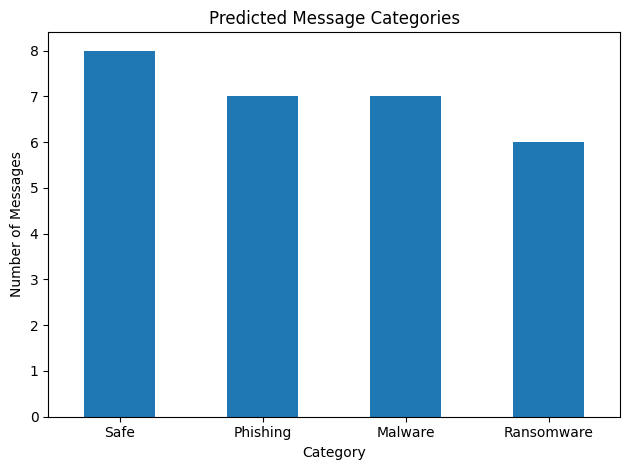

,Number of messages
predicted_category,
Safe,8
Phishing,7
Malware,7
Ransomware,6


In [6]:
# Count messages in the required category order.
category_order = ["Safe", "Phishing", "Malware", "Ransomware"]
category_counts = df["predicted_category"].value_counts().reindex(
    category_order, fill_value=0
)

category_counts.plot(kind="bar")
plt.title("Predicted Message Categories")
plt.xlabel("Category")
plt.ylabel("Number of Messages")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

display(category_counts.rename("Number of messages").to_frame())

### Q4 – Live new-message demonstration

Enter a new sanitized sample message below. Do not use real suspicious links, personal information or attachments. The classifier will display its category, matched keywords, score, risk level and recommended action.

In [ ]:
new_message = input("Enter a new sanitized message: ")

category, matched, score = classify_message(new_message)
demo_row = {
    "predicted_category": category,
    "keyword_score": score
}
risk, action = add_risk_and_action(demo_row)

print("\nPredicted category:", category)
print("Matched keywords:", matched if matched else "None")
print("Keyword score:", score)
print("Risk level:", risk)
print("Recommended action:", action)

### Q4 – Observation
High-risk results require human verification because keyword scores are only indicators. A human analyst should consider the sender, context and other evidence before taking action. Do not automatically delete messages or isolate systems based only on this simple classifier.

## Q5. Responsible Use, Reflection and File Saving (5 marks)

### Aim
Document privacy, bias, false alarms, accountability and human review, then save the final result.

### Responsible-use points

In [ ]:
responsible_use = [
    "Privacy: remove personal identifiers before analysis.",
    "Bias: keyword lists may not cover every writing style or language.",
    "False alarms: safe messages may contain warning words.",
    "Accountability: humans remain responsible for the final decision.",
    "Human review: high-risk or unclear cases must be checked."
]

for point in responsible_use:
    print("-", point)

### Conclusion

This lab demonstrates how transparent, rule-based AI can support basic cyber-security message screening. Keyword matching makes the classification process simple to understand because the system shows which words influenced its prediction. The classifier can identify common indicators of phishing, malware and ransomware in the supplied sample dataset. It also assigns risk levels and suggests cautious actions.

However, the system has limitations. It may miss attacks that use unfamiliar words, and it may incorrectly flag legitimate messages that contain suspicious keywords. The classroom dataset is small and does not represent every real-world message. Therefore, this tool should be used only as an initial aid. Privacy must be protected, and a human analyst must review high-risk or unclear cases before taking action.

### Save the final result

The following cell saves the completed classification table, including predicted category, matched keywords, keyword score, correctness, risk level and recommended action, as `Lab1_Final_Result.csv`.

In [ ]:
output_file = "Lab1_Final_Result.csv"
df.to_csv(output_file, index=False)
print("Saved:", output_file)

# In Google Colab, download the result file.
try:
    from google.colab import files
    files.download(output_file)
except ImportError:
    print("The CSV is saved in the current working directory.")

## Submission checklist

- [x] Executable and commented Colab notebook
- [x] Manual classification table for ten messages
- [x] Keyword lists and classifier function
- [x] Complete prediction and accuracy table
- [x] Risk/action table and labelled bar chart
- [x] New-message demonstration
- [x] Responsible-use note and conclusion
- [x] Code to save `Lab1_Final_Result.csv`

**Before submission:** Run all cells from top to bottom, check the displayed outputs, and keep the generated `Lab1_Final_Result.csv` with your notebook.